# Random Forest: advanced training

This is the latest experiment. The earlier baseline and optimized notebooks remain as historical evidence. These cells load and verify the completed run. They do not repeat training.

Random Forest because energy consumption may depend on complicated relationships between previous usage, time and other features. Random Forest can capture nonlinear patterns and interactions by combining many decision trees.

## 1. Load Python tools and find the project
X is the table of inputs, y is the actual energy usage. The saved model contains its own preprocessing.

This first cell imports the Python tools and our project functions. It prepares the notebook to read data, load the trained model and calculate results. No training happens in this cell.

In [22]:
from pathlib import Path
import sys, json
import joblib
import numpy as np
import pandas as pd
from IPython.display import display, Image
start = Path.cwd()
ROOT = next(p for p in [start, *start.parents] if (p / "src" / "advanced_training.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.advanced_training import make_model, extended_scores
from src.regression_common import load_data

## 2. Load the saved run and its original data
There are 15 named inputs at the model boundary. Feature engineering happens inside the model. Its metadata records the exact data directory and settings.

This cell reads the saved experiment settings and loads our prepared training and test data. X contains the inputs, and y contains the actual energy readings. We have 28,511 training rows and 5,857 test rows. This cell loads data; it does not train the model.

In [21]:
KIND = 'forest'
OUTPUT_DIR = ROOT / 'random forest' / "outputs_advanced"
metadata = json.loads((OUTPUT_DIR / "run_metadata.json").read_text())
settings = metadata["settings"]
X_train, X_test, y_train, y_test = load_data(metadata["input_directory"])
print("Training rows:", len(X_train), "Test rows:", len(X_test))

Training rows: 28511 Test rows: 5857


## 3. Explain the validation design
TimeSeriesSplit creates five expanding training windows. Every validation window occurs after its fitting data. We screen candidates on the last two windows, then compare finalists across all five. The previous optimized configuration is always evaluated as a finalist. These tuning scores are not an independent nested-CV estimate.

We used five time-series validation folds. Each round trains on earlier readings and checks later readings. We first screened configurations using two folds, then evaluated the finalists using all five. This cell displays the saved experiment details; it does not run training again.

In [23]:
display(pd.read_csv(OUTPUT_DIR / "fold_boundaries.csv"))
trials = pd.read_csv(OUTPUT_DIR / "validation_trials.csv")
print("Screening trials:", (trials.phase == "screen").sum())
print("Full five-fold trials:", (trials.phase == "full_cv").sum())

,fold,fit_rows,validation_rows,fit_start,fit_end,validation_start,validation_end
0,1,4756,4751,2018-01-08 00:15:00,2018-02-26 13:00:00,2018-02-26 13:15:00,2018-04-17 00:45:00
1,2,9507,4751,2018-01-08 00:15:00,2018-04-17 00:45:00,2018-04-17 01:00:00,2018-06-05 12:30:00
2,3,14258,4751,2018-01-08 00:15:00,2018-06-05 12:30:00,2018-06-05 12:45:00,2018-07-25 00:15:00
3,4,19009,4751,2018-01-08 00:15:00,2018-07-25 00:15:00,2018-07-25 00:30:00,2018-09-12 12:00:00
4,5,23760,4751,2018-01-08 00:15:00,2018-09-12 12:00:00,2018-09-12 12:15:00,2018-10-31 23:45:00


Screening trials: 53
Full five-fold trials: 9


## 4. Understand the candidates
Linear Regression tests spline shapes, weekend schedules, removing load level and fit-only weighting. It still uses LinearRegression to learn coefficients. Random Forest tests tree settings, calendar features, weighting, and predicting either usage directly or its change since the previous interval. For change prediction, the saved model adds the previous usage back automatically. No SVR is trained.

Each row shows one model configuration evaluated across five time-series folds. We sorted the configurations by average validation RMSE, with the lowest first. This helped us choose the settings. High-load MAE was also reported, but RMSE was the selection criterion

In [24]:
display(trials.loc[trials.phase == "full_cv", ["RMSE_kWh", "MAE_kWh", "R2", "HighLoad_MAE", "RMSE_std", "specification"]].sort_values("RMSE_kWh"))

,RMSE_kWh,MAE_kWh,R2,HighLoad_MAE,RMSE_std,specification
60,9.641221,4.634249,0.907484,11.994093,0.861213,"{""half_life_days"": null, ""high_weight"": 1.0, ""..."
57,9.659968,4.646534,0.907123,12.015102,0.862329,"{""half_life_days"": null, ""high_weight"": 1.0, ""..."
58,9.733048,4.674563,0.905692,12.060684,0.908750,"{""half_life_days"": 90, ""high_weight"": 1.0, ""ma..."
61,9.733418,4.674939,0.905675,12.062129,0.915004,"{""half_life_days"": 90, ""high_weight"": 1.0, ""ma..."
56,9.738433,4.690225,0.905591,11.900888,0.909937,"{""half_life_days"": 90, ""high_weight"": 1.3, ""ma..."
54,9.870816,4.758563,0.902745,11.900587,1.065382,"{""half_life_days"": 90, ""high_weight"": 1.3, ""ma..."
53,9.897095,4.811252,0.902405,11.906126,0.969715,"{""previous"": {""feature_mode"": ""context"", ""max_..."
59,9.907500,4.829482,0.902122,11.825996,1.036728,"{""half_life_days"": null, ""high_weight"": 1.3, ""..."
55,9.943825,4.790863,0.901322,11.958937,1.102050,"{""half_life_days"": null, ""high_weight"": 1.0, ""..."


## 5. Inspect the chosen configuration
The lowest average five-fold RMSE chooses the configuration. MAE and high-load MAE show trade-offs, but the test set does not select the winner. An untrained estimator is only a recipe; .fit(X, y) learns its parameters.

This cell displays our selected settings and the number of engineered features. It also creates an untrained model with those settings so we can inspect its structure. Creating the model does not train it; training requires the fit method.

| Setting | Your value | Very simple meaning |
|---|---:|---|
| `n_estimators` | **1000** | Build 1,000 decision trees and combine their predictions. |
| `max_depth` | **None** | Do not set a fixed maximum number of levels in each tree. Other stopping rules still apply. |
| `min_samples_leaf` | **2** | A final branch must contain at least two training examples. |
| `min_samples_split` | **2** | A branch needs at least two examples before a split can be considered. The other rules must also be satisfied. |
| `max_features` | **0.6** | At each split, consider a random selection of roughly 60% of the available features. |
| `max_samples` | **None** | For each tree, draw a training-set-sized sample. Some examples can appear more than once. |

In [14]:
print(json.dumps(settings["selected_specification"], indent=2))
print("Raw inputs:", settings["raw_input_features"], "Engineered inputs:", settings["transformed_features"])
untrained = make_model(KIND, settings["selected_specification"])
print(untrained)

{
  "half_life_days": null,
  "high_weight": 1.0,
  "max_depth": null,
  "max_features": 0.6,
  "max_samples": null,
  "min_samples_leaf": 2,
  "min_samples_split": 2,
  "n_estimators": 1000,
  "schedule": "harmonics",
  "target_mode": "delta",
  "use_load": false
}
Raw inputs: 15 Engineered inputs: 70
AdvancedEnergyRegressor(estimator=Pipeline(steps=[('features',
                                                   ScheduleFeatures(schedule='harmonics',
                                                                    use_load=False)),
                                                  ('regressor',
                                                   RandomForestRegressor(max_features=0.6,
                                                                         min_samples_leaf=2,
                                                                         n_estimators=1000,
                                                                         n_jobs=4,
                                  

## 6. Inspect the final scores
The selected model is refitted on all 28,511 January-October training rows. MAE and RMSE are measured in kWh; lower is better. R2 is not accuracy percent. HighLoad_MAE includes only actual usage >= 50 kWh. cv_mean averages fold metrics, while cv_pooled computes metrics from all out-of-fold predictions together.

This cell displays the saved evaluation results. I focus on the test row to explain performance on later observations not used for fitting. MAE and RMSE measure overall errors, while HighLoad_MAE measures errors during high-consumption intervals. Lower errors are better, and R² is not percentage accuracy.

In [15]:
display(pd.read_csv(OUTPUT_DIR / "metrics.csv"))

,model,split,n_rows,MAE_kWh,RMSE_kWh,R2,HighLoad_MAE,high_load_rows
0,Random Forest Regression,cv_mean,23755,4.634249,9.641221,0.907484,11.994093,NaN
1,Random Forest Regression,cv_pooled,23755,4.634249,9.679609,0.907171,12.040025,5698.0
2,Persistence,cv_pooled,23755,6.062173,13.512722,0.819094,15.604161,5698.0
3,Random Forest Regression,train,28511,1.945410,4.263375,0.983976,5.057310,7443.0
4,Random Forest Regression,test,5857,3.644501,7.734955,0.938272,9.514981,1491.0
5,Persistence,test,5857,5.155235,11.812549,0.856036,12.419591,1491.0


## 7. Verify the exported model
Loading this file and predicting again must reproduce the saved test results. This checks that preprocessing, target handling and nonnegative clipping were saved correctly.

This cell loads our trained model and generates predictions from the test inputs. It checks that those predictions match our saved results, then recalculates the evaluation metrics. This verifies that the model was saved and loaded correctly. No retraining happens here.

In [16]:
model = joblib.load(OUTPUT_DIR / "model.joblib")
predictions = model.predict(X_test)
saved = pd.read_csv(OUTPUT_DIR / "test_predictions.csv", index_col=0)
np.testing.assert_allclose(predictions, saved.predicted_kWh, rtol=1e-10, atol=1e-8)
display(pd.DataFrame([extended_scores("Reloaded model", "test", y_test, predictions)]))
print("Saved model verified.")

,model,split,n_rows,MAE_kWh,RMSE_kWh,R2,HighLoad_MAE,high_load_rows
0,Reloaded model,test,5857,3.644501,7.734955,0.938272,9.514981,1491


Saved model verified.


## 8. Read the error plots
Look at how predictions follow usage changes and where large errors remain. The model is a one-interval-ahead forecast with previous actual meter readings available, not a full day-ahead prediction.

This graph compares actual and predicted usage over time. Where the lines follow each other closely, the model predicts well. Gaps show prediction errors.

Each point compares one prediction with its actual value. Points close to the diagonal represent smaller errors.

This graph shows the distribution of prediction errors. Errors near zero are small, while values far from zero show larger mistakes.

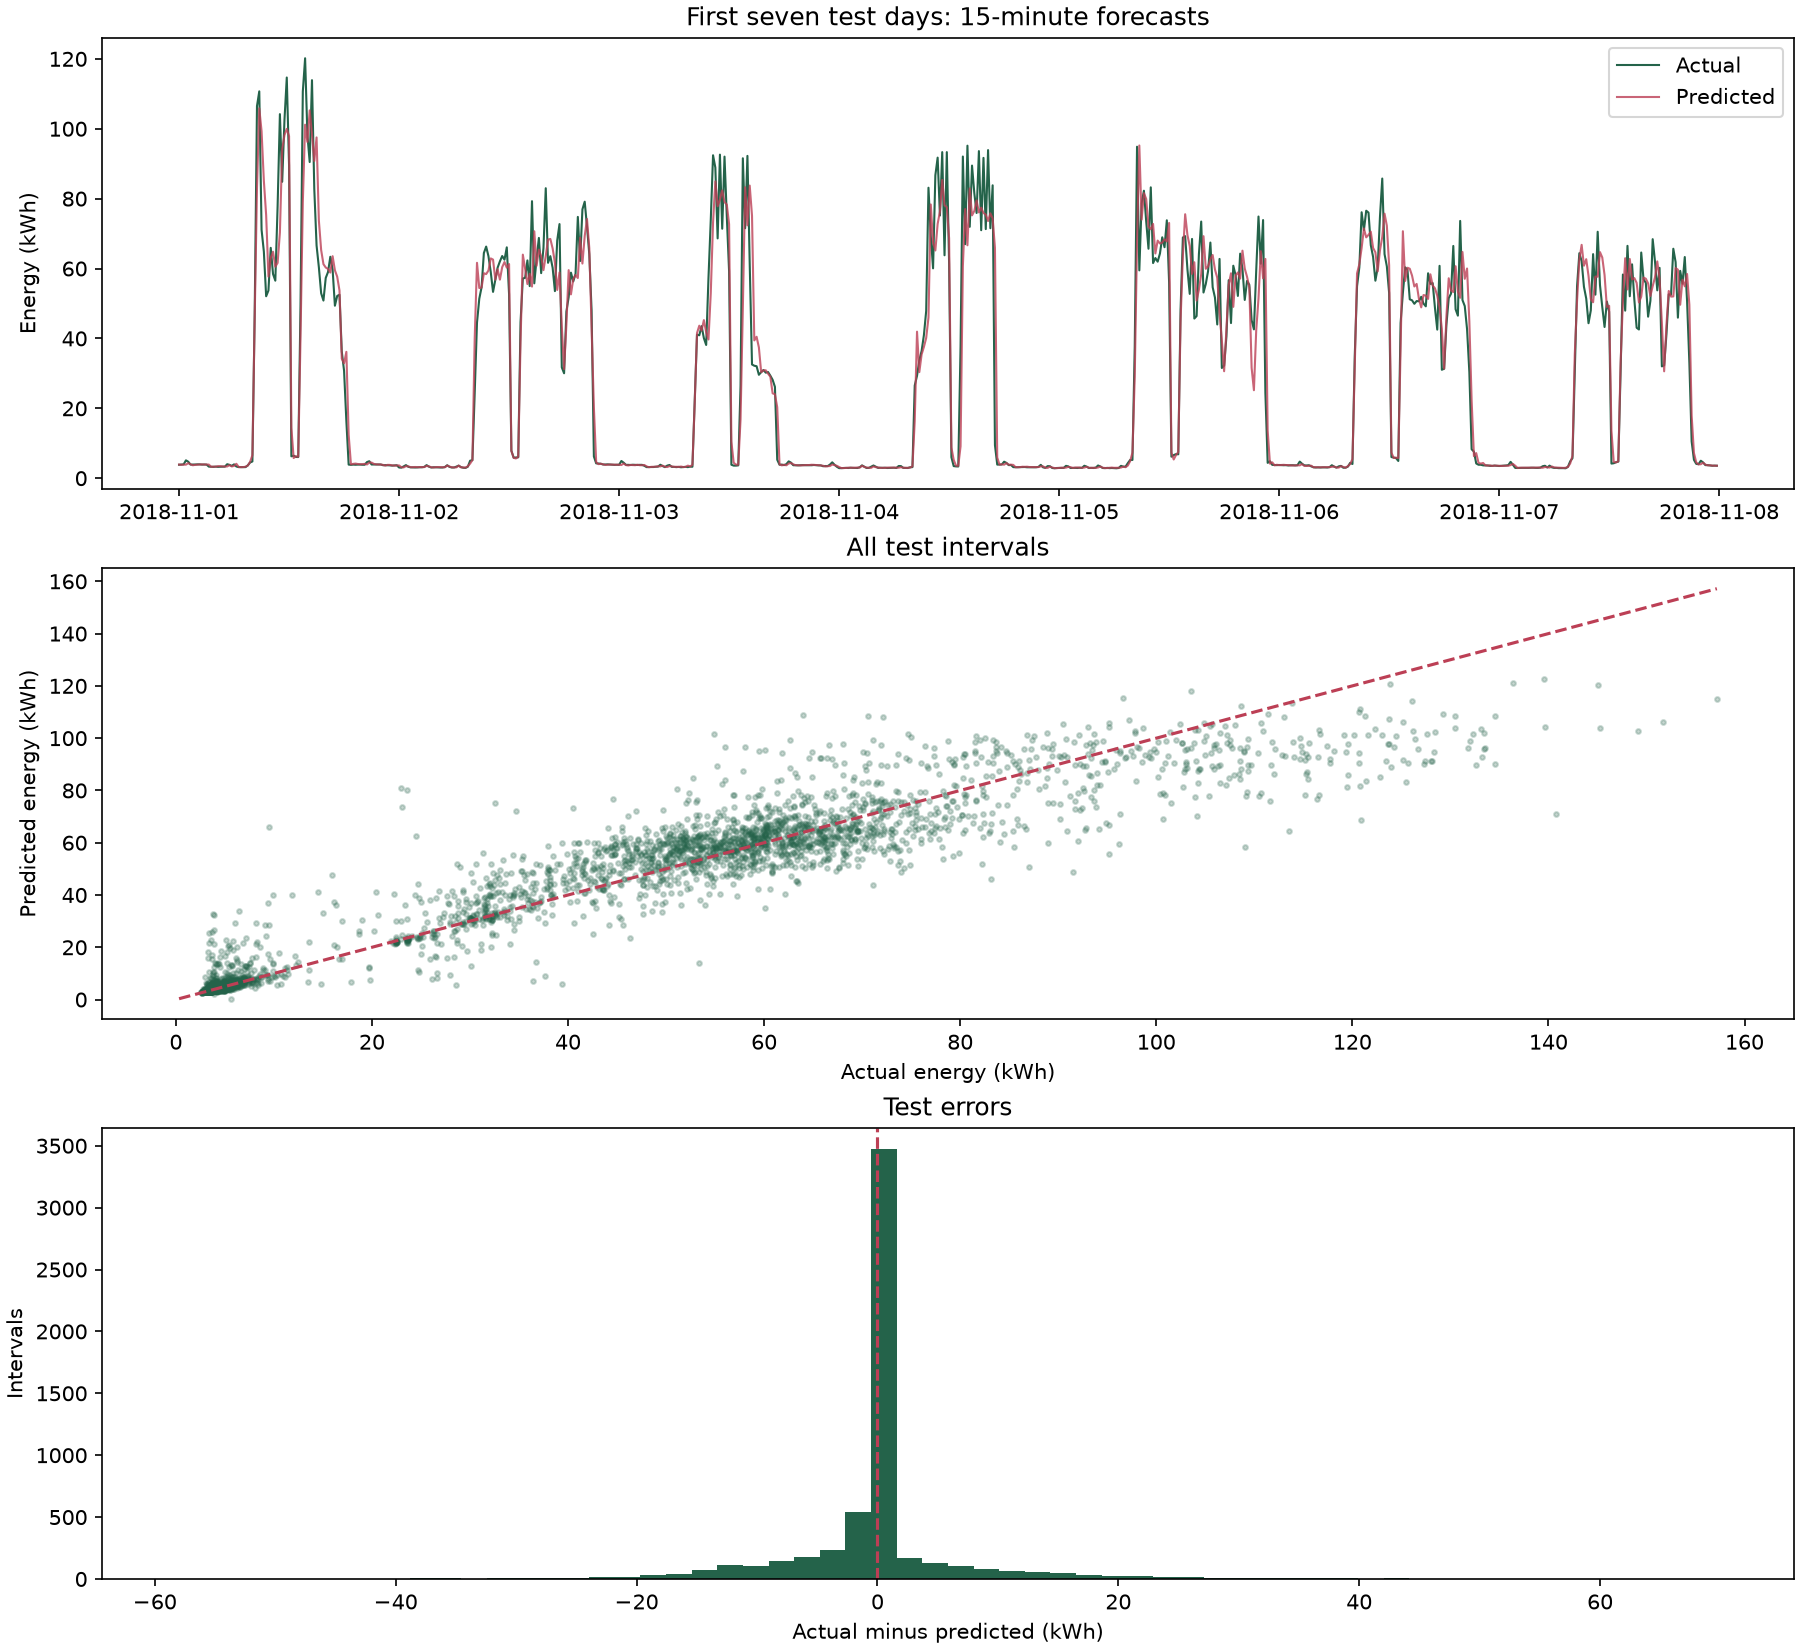

In [17]:
display(Image(filename=str(OUTPUT_DIR / "evaluation.png")))

## 9. Check assumptions and robustness
The interpolation sensitivity excludes the known imputed test target and every row whose saved lag/rolling features could depend on it. It does not repair all upstream preprocessing assumptions. The no-load check uses the last CV fold and does not choose a new model.

This section checks weaknesses in the evaluation. We examined the interpolation issue, performance without load level, and monthly results. We also documented limitations rather than claiming the model is perfect.

In [18]:
display(pd.read_csv(OUTPUT_DIR / "interpolation_sensitivity.csv"))
display(pd.read_csv(OUTPUT_DIR / "load_level_ablation.csv"))
display(pd.read_csv(OUTPUT_DIR / "test_monthly_metrics.csv"))
for note in metadata["limitations"]:
    print("-", note)

,model,split,n_rows,MAE_kWh,RMSE_kWh,R2,HighLoad_MAE,high_load_rows
0,Selected configuration,exclude_interpolation_influence,5759,3.630808,7.718044,0.938534,9.548005,1453


,model,split,n_rows,MAE_kWh,RMSE_kWh,R2,HighLoad_MAE,high_load_rows
0,Selected settings without load_level,last_cv_fold,4751,4.12012,8.934139,0.915472,11.357639,1068


,model,split,n_rows,MAE_kWh,RMSE_kWh,R2,HighLoad_MAE,high_load_rows
0,Random Forest Regression,2018-11,2880,4.500041,8.868518,0.932566,10.374124,901
1,Random Forest Regression,2018-12,2976,2.817748,6.452572,0.942953,8.202967,590
2,Random Forest Regression,2019-01,1,0.104954,0.104954,NaN,NaN,0


- Forecasts are one interval ahead (15 minutes), with previous actual readings available before each prediction. This is not a day-ahead test.
- The selected transformer ignores load_level. It remains in the 15-column input schema, but no upcoming operating-load category is required.
- The supplied preprocessing shifts midnight rows to the next day; the original interval timestamp convention remains an assumption.
- The supplied preprocessing interpolates the target at 2018-11-08 00:00 using a future reading. This affects that test target and later lag/rolling features. Test results describe those supplied artifacts, not a fully causal evaluation of raw measurements.
- Upstream feature selection used the entire supplied training period, including September/October. Validation is provisional conditional on that fixed feature set; strict validation needs feature selection refitted on the earlier fitting period.
- The preprocessing notebook already inspected the test persistence score and

## 10. Reproduce only when needed
The experiment is already trained. The command below reruns the search and replaces only this model's outputs_advanced folder.

```bash
python src/advanced_training.py --model forest --train
```

Use `python src/show_model_results.py` for the terminal summary without retraining. Read `../reports/ADVANCED_TRAINING_REPORT.md` for the comparison and remaining limitations.